Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-ispolzovanie-resnet-modeley-svyaz-resnet-s-dropout-i-bustingom

In [16]:
from torchvision import models
from PIL import Image

model = models.resnet50()
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [17]:
resnet_weights = models.ResNet50_Weights.DEFAULT
resnet_weights

ResNet50_Weights.IMAGENET1K_V2

In [18]:
cats = resnet_weights.meta['categories']
cats

['tench',
 'goldfish',
 'great white shark',
 'tiger shark',
 'hammerhead',
 'electric ray',
 'stingray',
 'cock',
 'hen',
 'ostrich',
 'brambling',
 'goldfinch',
 'house finch',
 'junco',
 'indigo bunting',
 'robin',
 'bulbul',
 'jay',
 'magpie',
 'chickadee',
 'water ouzel',
 'kite',
 'bald eagle',
 'vulture',
 'great grey owl',
 'European fire salamander',
 'common newt',
 'eft',
 'spotted salamander',
 'axolotl',
 'bullfrog',
 'tree frog',
 'tailed frog',
 'loggerhead',
 'leatherback turtle',
 'mud turtle',
 'terrapin',
 'box turtle',
 'banded gecko',
 'common iguana',
 'American chameleon',
 'whiptail',
 'agama',
 'frilled lizard',
 'alligator lizard',
 'Gila monster',
 'green lizard',
 'African chameleon',
 'Komodo dragon',
 'African crocodile',
 'American alligator',
 'triceratops',
 'thunder snake',
 'ringneck snake',
 'hognose snake',
 'green snake',
 'king snake',
 'garter snake',
 'water snake',
 'vine snake',
 'night snake',
 'boa constrictor',
 'rock python',
 'Indian cobr

In [19]:
transforms = resnet_weights.transforms()
transforms

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

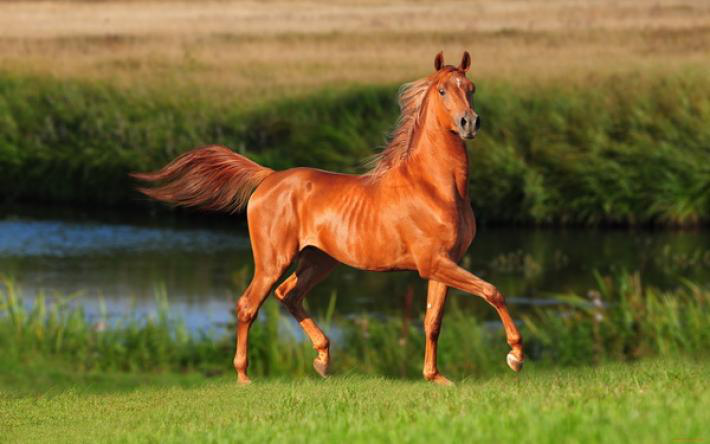

In [20]:
img = Image.open('horse.jpg').convert('RGB')
img

In [21]:
img = transforms(img).unsqueeze(0)
img.shape

torch.Size([1, 3, 224, 224])

In [22]:
%%time

model = models.resnet50(weights=resnet_weights)
model.eval()
predict = model(img).squeeze()
res = predict.softmax(dim=0).sort(descending=True)

for s, i in zip(res[0][:5], res[1][:5]):
    print(f"{cats[i]}: {s:.4f}")

sorrel: 0.4376
hartebeest: 0.0034
gazelle: 0.0028
impala: 0.0028
muzzle: 0.0019
CPU times: total: 891 ms
Wall time: 638 ms


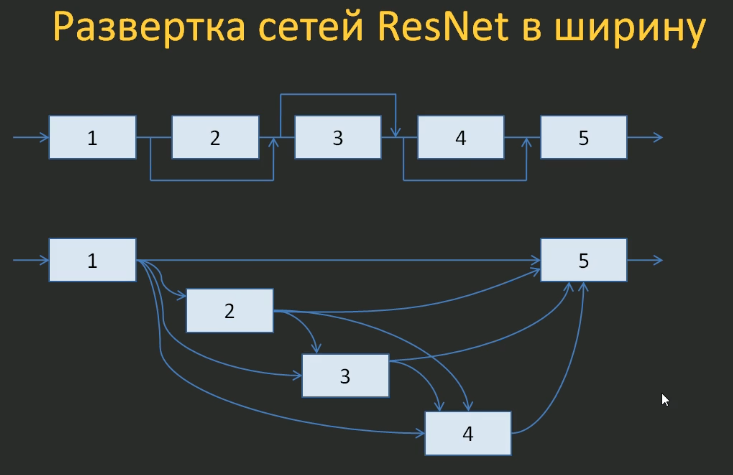

из-за скип-коннешенов можно считать, что по одному из путей вход сразу пробрасывается на выход. Развивая эту мысль, можно представить модель в виде параллельных моделей. Это роднит подход с алгоритмом дропаут, который, отключая нейроны, обучает каждый раз новую подмодель нашей модели. 

Также можно считать, что каждый блок сети РесНет учится на ошибках предыдущего блока, что перекликается с работой бустинга